# IND320 Project Work, Part 2

**Course:** IND320 Data to Decision  
**Student:** Sara Christine Gjerløw  

**GitHub repository:** https://github.com/SaraGjerlow/ind320-SaraGjerlow  
**Streamlit app:** https://ind320-saragjerlow.streamlit.app

In this part the CSV file from part 1 is replaced by the NVE API. I also collect
cross-border power flow from ENTSO-E, store it in Cassandra with Spark, read it
back out, and put it into MongoDB. The Streamlit app reads from MongoDB.

## 1. Imports

In [1]:
import os
import tomllib
from pathlib import Path
import time
import matplotlib.pyplot as plt
import pandas as pd
import requests
from cassandra.cluster import Cluster
from entsoe import EntsoePandasClient
from pymongo.mongo_client import MongoClient
from pymongo.server_api import ServerApi
from pyspark.sql import SparkSession

## 2. Database connections

The MongoDB connection string and the ENTSO-E token are kept in
`.streamlit/secrets.toml`. That file is in `.gitignore`, so it never reaches
GitHub, and the app reads the same file.

In [2]:
# Both secrets live in the same file.
with open(Path("../.streamlit/secrets.toml"), "rb") as f:
    secrets = tomllib.load(f)

mongo_uri = secrets["mongo"]["uri"]
entsoe_token = secrets["entsoe"]["token"]

# Check the MongoDB connection before using it later.
mongo_client = MongoClient(mongo_uri, server_api=ServerApi("1"))

try:
    mongo_client.admin.command("ping")
    print("Connected to MongoDB.")
except Exception as error:
    print(error)

# Check that the token loaded, without printing it.
print("ENTSO-E token loaded:", len(entsoe_token), "characters")

Connected to MongoDB.
ENTSO-E token loaded: 36 characters


## 3. Magasinstatistikk from the NVE API

Part 1 read a CSV file. Here the same data comes straight from NVE's API, so
there is no data file in the repository.

In [3]:
API_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(API_URL)
response.raise_for_status()  # Stops here if the request failed.

# One object per measurement, which fits straight into a DataFrame.
df = pd.DataFrame(response.json())

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (14922, 11)


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


## 4. Areas covered by the API

The rows are several time series stacked on top of each other, one per area. NVE
has a separate endpoint that lists the areas, which I use to find out what the
area codes mean.

In [4]:
AREAS_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOmr%C3%A5der"

# The response is a list with one object inside it, so [0] unwraps it.
areas_raw = requests.get(AREAS_URL).json()[0]

# Put the three groups into one table.
rows = []
for group_name, group in areas_raw.items():
    for area in group:
        area["group"] = group_name
        rows.append(area)

areas = pd.DataFrame(rows)
areas

,navn,navn_langt,beskrivelse,omrType,omrnr,group
0,Norge,Norge,Hele landet,NO,0,land
1,NO 1,Elspotområde 1,Sørøst-Norge. Omfatter østlige del av Østlande...,EL,1,elspot
2,NO 2,Elspotområde 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...,EL,2,elspot
3,NO 3,Elspotområde 3,Midt-Norge. Omfatter nordre og vestlige del av...,EL,3,elspot
4,NO 4,Elspotområde 4,Nord-Norge. Omfatter resten av Trøndelag og No...,EL,4,elspot
5,NO 5,Elspotområde 5,Vest-Norge. Omfatter midtre del av Vestland op...,EL,5,elspot
6,VASS1,Vassdragsområde 1,"Sørøst-Norge. Østlandet, Agder og deler av Rog...",VASS,1,vassdrag
7,VASS2,Vassdragsområde 2,Vest-Norge. Resten av Rogaland og Vestland.,VASS,2,vassdrag
8,VASS3,Vassdragsområde 3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl...",VASS,3,vassdrag
9,VASS4,Vassdragsområde 4,Nord-Norge. Resten av Nordland og nordover.,VASS,4,vassdrag


NVE defines ten areas: the whole country (NO 0), five electricity price areas
(EL 1 to 5) and four watercourse areas (VASS 1 to 4). The next cell checks which
of them actually appear in the data.

In [5]:
# Count the rows per area.
print(df.groupby(["omrType", "omrnr"]).size())

omrType  omrnr
EL       1        1658
         2        1658
         3        1658
         4        1658
         5        1658
NO       0        1658
VASS     1        1658
         2        1658
         3        1658
dtype: int64


Only nine areas show up. VASS 4 is defined but never reported. That matters for
the app, because an area selector built from the list alone would offer a choice
that returns nothing.

## 5. Plots from part 1, now from the API

Same preparation as in part 1. Keep the national total, sort by date, and
translate the column names to English.

In [6]:
# Keep the national total only.
national = df[df["omrType"] == "NO"].copy()

# Turn the dates into real dates and sort by them.
national["dato_Id"] = pd.to_datetime(national["dato_Id"])
national = national.sort_values("dato_Id")

# Keep the date and the five measurement columns.
data = national[[
    "dato_Id",
    "fyllingsgrad",
    "kapasitet_TWh",
    "fylling_TWh",
    "fyllingsgrad_forrige_uke",
    "endring_fyllingsgrad",
]]

# English column names, with the unit in the name.
data = data.rename(columns={
    "dato_Id": "Date",
    "fyllingsgrad": "Fill level (fraction)",
    "kapasitet_TWh": "Capacity (TWh)",
    "fylling_TWh": "Stored energy (TWh)",
    "fyllingsgrad_forrige_uke": "Fill level previous week (fraction)",
    "endring_fyllingsgrad": "Change in fill level (fraction)",
})

# Date as index, so it becomes the x-axis.
data = data.set_index("Date")

print("Rows and columns:", data.shape)
print("First date:", data.index.min())
print("Last date:", data.index.max())
data.head()

Rows and columns: (1658, 5)
First date: 1995-01-08 00:00:00
Last date: 2026-10-11 00:00:00


,Fill level (fraction),Capacity (TWh),Stored energy (TWh),Fill level previous week (fraction),Change in fill level (fraction)
Date,,,,,
1995-01-08,0.607988,87.43758,53.161003,0.752631,-0.144643
1995-01-15,0.582088,87.43758,50.896374,0.607988,-0.025900
1995-01-22,0.562121,87.43758,49.150486,0.582088,-0.019967
1995-01-29,0.534222,87.43758,46.711033,0.562121,-0.027899
1995-02-05,0.506221,87.43758,44.262720,0.534222,-0.028001


### Each column separately

One figure per column, so each variable gets its own scale.

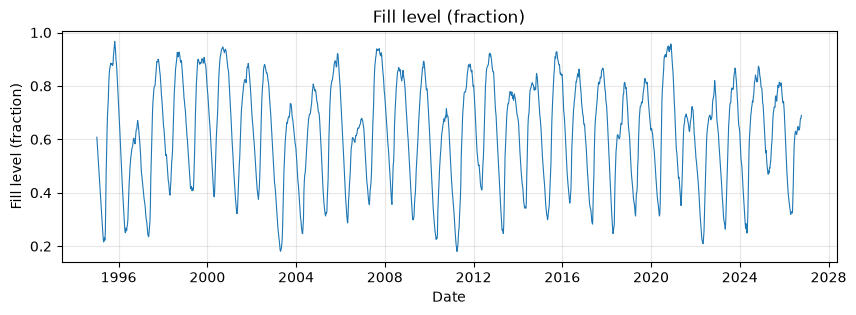

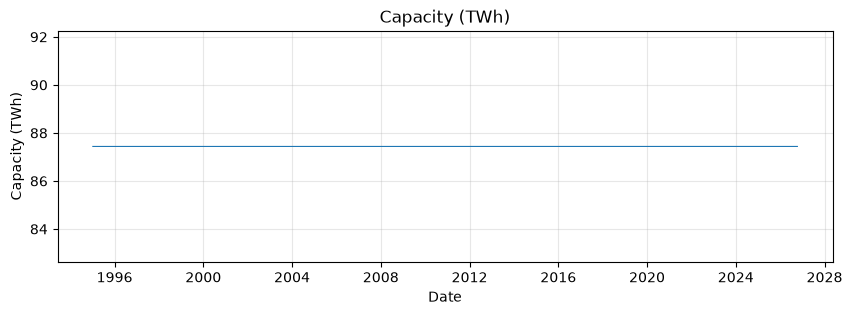

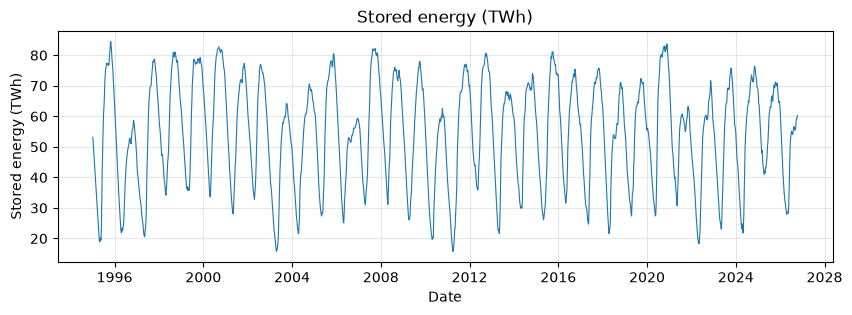

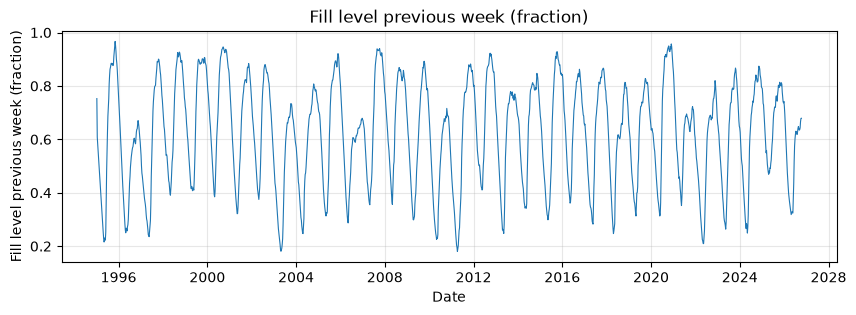

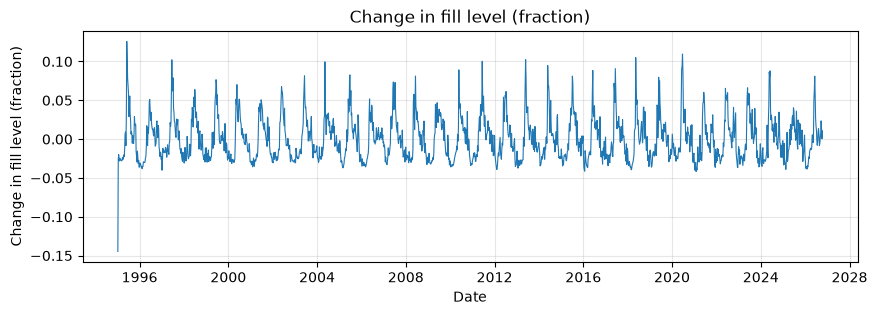

In [7]:
for column in data.columns:
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.plot(data.index, data[column], linewidth=0.8)
    ax.set_title(column)
    ax.set_xlabel("Date")
    ax.set_ylabel(column)
    ax.grid(alpha=0.3)
    plt.show()

### All columns together

The columns have different units, so some of them would be flat lines along the
bottom if I drew them as they are. Each column is rescaled to run from 0 to 1
instead. The real values can no longer be read off the plot.

Capacity is left out, because it is the same value in every row.

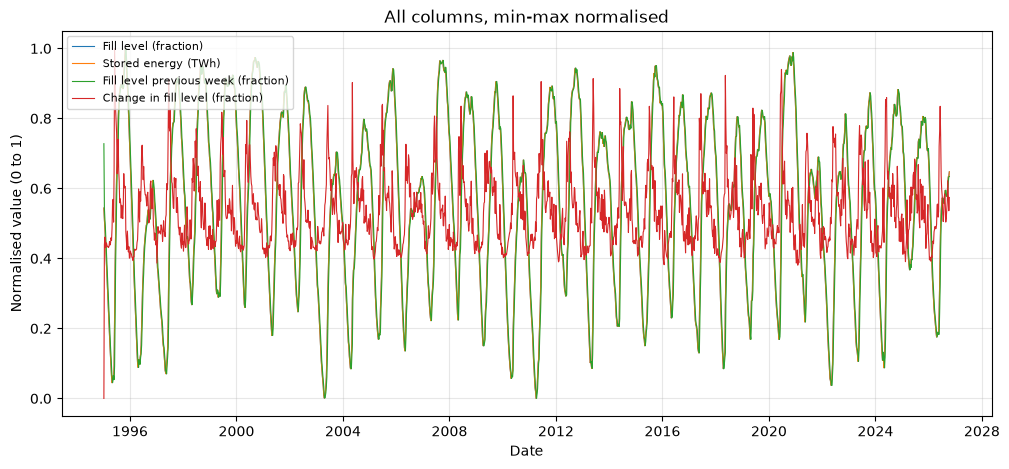

In [8]:
# The four columns to plot, capacity excluded.
columns_to_plot = [
    "Fill level (fraction)",
    "Stored energy (TWh)",
    "Fill level previous week (fraction)",
    "Change in fill level (fraction)",
]

fig, ax = plt.subplots(figsize=(12, 5))

for column in columns_to_plot:
    values = data[column]
    # Rescale the column to run from 0 to 1.
    normalised = (values - values.min()) / (values.max() - values.min())
    ax.plot(data.index, normalised, linewidth=0.8, label=column)

ax.set_title("All columns, min-max normalised")
ax.set_xlabel("Date")
ax.set_ylabel("Normalised value (0 to 1)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="upper left")
plt.show()

## 6. ENTSO-E cross-border flows

ENTSO-E publishes the power flow across every border in Europe. The API answers
in XML, so I use the `entsoe-py` package, which calls the same API and returns
pandas objects.

Flow has a direction. Asking from NO2 to a neighbour gives power leaving Norway,
and the opposite query gives power coming in, so each connection needs two
calls.

This cell takes about fifteen minutes.

In [9]:
entsoe_client = EntsoePandasClient(api_key=entsoe_token)

# The API requires timezone-aware timestamps.
end = pd.Timestamp.now(tz="Europe/Oslo").normalize()
start = end - pd.DateOffset(years=2)

# The four subsea interconnectors from bidding zone NO2.
CONNECTIONS = {
    "Skagerrak (DK1)": "DK_1",
    "NorNed (NL)": "NL",
    "NordLink (DE-LU)": "DE_LU",
    "North Sea Link (GB)": "GB",
}

NORWAY_ZONE = "NO_2"


def fetch_flows(zone_from, zone_to):
    """Ask ENTSO-E for one direction, and try again if the server fails.

    The server sometimes times out on these long queries, and one failure
    would otherwise throw away everything collected so far.
    """
    for attempt in range(5):
        try:
            return entsoe_client.query_crossborder_flows(
                zone_from, zone_to, start=start, end=end
            )
        except Exception as error:
            print("    attempt", attempt + 1, "failed:", type(error).__name__)
            time.sleep(30)

    raise RuntimeError(f"Gave up on {zone_from} to {zone_to}")


rows = []

for name, neighbour in CONNECTIONS.items():
    # Export is power leaving Norway, import is power entering Norway.
    export = fetch_flows(NORWAY_ZONE, neighbour)
    imported = fetch_flows(neighbour, NORWAY_ZONE)

    # The resolution changes during the period, so both series are
    # resampled to hourly.
    export = export.resample("1h").mean()
    imported = imported.resample("1h").mean()

    for timestamp, value in export.items():
        rows.append({
            "connection": name,
            "direction": "export",
            "timestamp": timestamp,
            "flow_mw": float(value),
        })

    for timestamp, value in imported.items():
        rows.append({
            "connection": name,
            "direction": "import",
            "timestamp": timestamp,
            "flow_mw": float(value),
        })

    print(name, "done")

flows = pd.DataFrame(rows)

print("Rows and columns:", flows.shape)
flows.head()

Skagerrak (DK1) done


KeyboardInterrupt: 

## 7. Cassandra and Spark

Cassandra runs in a Docker container on my laptop. Spark both writes the data
into it and reads it back out.

Spark runs on Java, so it needs to know where Java is installed.

In [ ]:
# This path came from running /usr/libexec/java_home in a terminal.
os.environ["JAVA_HOME"] = "/Library/Java/JavaVirtualMachines/microsoft-17.jdk/Contents/Home"

# "python" means the interpreter of the currently active environment.
os.environ["PYSPARK_PYTHON"] = "python"
os.environ["PYSPARK_DRIVER_PYTHON"] = "python"

# No separate Hadoop installation is used.
os.environ["PYSPARK_HADOOP_VERSION"] = "without"

A keyspace is Cassandra's version of a database. Replication factor 1 is the
smallest setup, which is enough for one local node.

In [ ]:
# Connect to the Cassandra container on the default port.
cluster = Cluster(["localhost"], port=9042)
session = cluster.connect()

session.execute("""
    CREATE KEYSPACE IF NOT EXISTS ind320
    WITH REPLICATION = {'class': 'SimpleStrategy', 'replication_factor': 1};
""")

session.set_keyspace("ind320")
print("Connected to Cassandra.")

Spark needs the DataStax Cassandra connector. The versions have to match, so the
connector is pinned to the one that fits Spark 3.5.1. Spark downloads it on the
first run, and some warnings at startup are normal.

In [ ]:
spark = (
    SparkSession.builder.appName("IND320")
    .config("spark.jars.packages",
            "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .config("spark.cassandra.connection.host", "localhost")
    .config("spark.cassandra.connection.port", "9042")
    .config("spark.sql.extensions",
            "com.datastax.spark.connector.CassandraSparkExtensions")
    .config("spark.sql.catalog.mycatalog",
            "com.datastax.spark.connector.datasource.CassandraCatalog")
    # My timestamps are UTC. Without this, Spark reads them as local time and
    # loses the hour that does not exist on the spring clock change.
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)

print("Spark version:", spark.version)

### Writing to Cassandra

Cassandra needs the table defined up front. The primary key decides how rows are
stored: grouped by connection and direction, and sorted by time inside each
group.

In [ ]:
# Dropped first, so the notebook can be run again from the top.
session.execute("DROP TABLE IF EXISTS crossborder_flows;")

session.execute("""
    CREATE TABLE IF NOT EXISTS crossborder_flows (
        connection text,
        direction text,
        timestamp timestamp,
        flow_mw double,
        PRIMARY KEY ((connection, direction), timestamp)
    );
""")

print("Table created.")

The data goes in through Spark. The timestamps are converted to UTC and the
timezone is removed first, which is the form the Cassandra column expects.

In [ ]:
flows_to_write = flows.copy()

# The timestamp column can end up as plain objects, so it is turned into
# real datetimes in UTC.
flows_to_write["timestamp"] = pd.to_datetime(flows_to_write["timestamp"], utc=True)

# Cassandra wants no timezone, so the offset is dropped.
flows_to_write["timestamp"] = flows_to_write["timestamp"].dt.tz_localize(None)

# Pandas DataFrame -> Spark DataFrame -> Cassandra table.
spark_flows = spark.createDataFrame(flows_to_write)

spark_flows.write.format("org.apache.spark.sql.cassandra") \
    .options(table="crossborder_flows", keyspace="ind320") \
    .mode("append").save()

print("Rows written to Cassandra:", spark_flows.count())

### Reading back from Cassandra

Loading the table into Spark and registering it as a view lets me pick the
columns with ordinary SQL. The result becomes a pandas DataFrame, which the
plots and MongoDB below use.

In [ ]:
spark.read.format("org.apache.spark.sql.cassandra") \
    .options(table="crossborder_flows", keyspace="ind320") \
    .load() \
    .createOrReplaceTempView("flows_view")

extracted = spark.sql("""
    SELECT connection, direction, timestamp, flow_mw
    FROM flows_view
""").toPandas()

print("Rows and columns:", extracted.shape)
extracted.head()

Rows that share a primary key overwrite each other in Cassandra, so I check that
everything I wrote actually came back.

This check found a real problem. Sixteen rows were missing, all at 02:00 on the
two nights in March when the clocks go forward. That hour does not exist in
Norwegian time, and Spark was reading my UTC timestamps as local time, so those
rows were pushed onto the next hour and wrote over it. Setting the Spark session
timezone to UTC fixed it, and nothing should be missing now.

In [ ]:
# Compare the keys written with the keys read back, so a mismatch shows up
# as the actual missing rows.
written_keys = set(
    zip(flows_to_write["connection"], flows_to_write["direction"], flows_to_write["timestamp"])
)
read_keys = set(
    zip(extracted["connection"], extracted["direction"], extracted["timestamp"])
)

missing = written_keys - read_keys

print("Written:", len(written_keys))
print("Read back:", len(read_keys))
print("Missing:", len(missing))
print("Missing flow values before writing:", flows_to_write["flow_mw"].isna().sum())

for key in sorted(missing):
    print(key)

## 8. Plots from the Spark data

### Pie chart: one connection, one year

The data is hourly, so one value in MW is one MWh. Summing a year for one
connection gives the total energy out of Norway and the total in, which is what
the two slices show.

In [ ]:
PIE_CONNECTION = "Skagerrak (DK1)"
PIE_YEAR = 2025

# Keep the rows for the chosen connection and year.
year_data = extracted[
    (extracted["connection"] == PIE_CONNECTION)
    & (extracted["timestamp"].dt.year == PIE_YEAR)
]

# One total per direction.
totals = year_data.groupby("direction")["flow_mw"].sum()

# Readable names for the chart.
labels = {"export": "Out of Norway", "import": "Into Norway"}

pie_labels = []
for direction in totals.index:
    pie_labels.append(labels[direction])

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(totals, labels=pie_labels, autopct="%1.1f%%", startangle=90)
ax.set_title(f"{PIE_CONNECTION}: energy in and out of Norway, {PIE_YEAR}")
plt.show()

print(totals.round(0))

### Line plot: the first month of a year

January of the chosen year, with one line per connection and direction.

In [ ]:
LINE_YEAR = 2025

# Keep January of the chosen year.
first_month = extracted[
    (extracted["timestamp"].dt.year == LINE_YEAR)
    & (extracted["timestamp"].dt.month == 1)
]

fig, ax = plt.subplots(figsize=(12, 5))

# Two lines per connection: one for each direction.
for connection in sorted(first_month["connection"].unique()):
    for direction in ["export", "import"]:
        series = first_month[
            (first_month["connection"] == connection)
            & (first_month["direction"] == direction)
        ].sort_values("timestamp")

        ax.plot(series["timestamp"], series["flow_mw"], linewidth=0.8,
                label=f"{connection}, {direction}")

ax.set_title(f"Cross-border flow, January {LINE_YEAR}")
ax.set_xlabel("Time")
ax.set_ylabel("Flow (MW)")
ax.grid(alpha=0.3)
ax.legend(fontsize=7, ncol=2)
fig.autofmt_xdate()
plt.show()

## 9. Insert into MongoDB

The app reads from MongoDB, because it cannot reach Cassandra on my laptop. The
data here is the same data Spark pulled out of Cassandra above.

In [ ]:
database = mongo_client["ind320"]
collection = database["crossborder_flows"]

# Emptied first, so running the notebook again does not duplicate anything.
collection.delete_many({})

# MongoDB stores dictionaries. to_dict("records") makes one per row.
collection.insert_many(extracted.to_dict("records"))

print("Documents in collection:", collection.count_documents({}))

### Closing the connections

Spark and Cassandra stay open until they are told to stop, so both are closed
once the data is in MongoDB.

In [ ]:
# Release the Spark and Cassandra connections.
spark.stop()
cluster.shutdown()
print("Connections closed.")

## 10. Log

This part of the project was harder than part 1, and most of that was because I
had to use tools I had never used before.

Replacing the CSV file with the NVE API was the easy part. The API hands over
everything on one endpoint, so there are no dates to ask for and nothing to
download by hand. I rebuilt the plots from part 1 on top of it. I also looked up
NVE's list of areas, because I did not actually know what NO, EL and VASS actually meant,
I had just been using the codes. It turned out that VASS 4 is in the list but
never shows up in the data, which would have left a dead option in the app if I
had not checked.

The ENTSO-E part was mostly waiting. Each connection needs two queries, one for
each direction, and eight queries over two years take about fifteen minutes. I
ran it more times than I needed to, because I kept changing something small
further down and then had to start over.

Cassandra, Spark and MongoDB were the parts I struggled the most. For a long time
I could not see why one dataset needed three different databases. It made sense
when I deployed the app: Cassandra sits in Docker on my own laptop, and
Streamlit Cloud cannot reach my laptop. So Cassandra is where the data is kept,
MongoDB is what the app is allowed to see, and Spark is what moves it between
them.

Then I noticed that 140160 rows went into Cassandra and only 140144 came back. I
assumed they were duplicates, but when I counted them there were none. Printing the
missing rows showed that all sixteen sat at 02:00 on the two
days the clocks go forward. Spark reads timestamps as local time, and that hour does not exist in Norway,
because the clocks jump from 02:00 to 03:00 when we change to summer time, so
it was pushed onto the next hour and wrote over it.
One line of configuration fixed it. I am glad I looked instead of accepting the
numbers.

In the app I joined the table page and the plot page from part 1 into one page,
which I like much better. The cross-border page is the one I used some time getting happy
with. My first version drew all eight lines at once and I found that difficult to read, so now it only shows the connection you pick on the left. I also added a
warning when a year is incomplete, because the two year window starts in
October, and my own pie chart for 2024 confused me until I understood that it
only covered three months. And if you pick a month with no data, the page now
says so instead of showing an empty box. Because you can pick months that are not next to each other, each
series is resampled to a continuous hourly index, so the line breaks instead of
drawing a straight jump from example January to April. 

## 11. AI declaration

Claude (Anthropic) was used for:
- Sparring when structuring the notebook and the app
- Explanations of Cassandra, Spark and MongoDB
- Suggesting and reviewing code

Gemini was used for:
- Concept clarification (Streamlit vs. Power BI, MongoDB, Cassandra)
- Environment setup and troubleshooting on macOS / VS Code
- Assistance for terminal commands

All code was run, tested and adjusted by me, and I have checked that I understand what
each cell does. NVE, ENTSO-E and Streamlit documentation were used as primary
sources.